In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import pandas as pd
import math
from scipy.integrate import solve_ivp, cumulative_trapezoid, quad
from scipy.interpolate import CubicSpline
from numba import njit, prange

In [2]:
# Set som plotting standards:
font = {'family' : 'serif',
        'weight' : 'normal',
        'size'   : 18}
mpl.rc('font', **font)

axes = {'facecolor': 'ghostwhite'}
mpl.rc('axes', **axes)

# Set custom color cycle
custom_colors= ['dodgerblue', 'red', 'limegreen', 'orange', 'orchid', 'black', 'slategrey', 
                'navy', 'magenta', 'forestgreen', 'lightblue', 'maroon', 'gold', 'lightcoral', 
                'mediumseagreen', 'darkorange', 'darkviolet', 'dimgray', 'darkblue', 'darkred',]
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=custom_colors)

# Set inside tickmarks
mpl.rcParams['xtick.direction'] = 'in'
mpl.rcParams['ytick.direction'] = 'in'
mpl.rcParams['xtick.minor.visible'] = True
mpl.rcParams['ytick.minor.visible'] = True

# Functions

In [3]:
from Functions import compute_for_sigmoidal

In [4]:
def compute_mfpt_with_robin_boundary(r_target, r_f, r_n, D0, Dn, A, b, kappa):
    """ Calculate the double integral: 
    integral from r_target to r_n of (-exp(phi(r)))dr * integral from r to r_0 of (exp(phi(s))/D(s))ds, 
    + exp(phi(r_target)) / kappa * integral from r_target to r_n of (exp(-phi(r)))dr,
    where phi(r) = -2 * ln(r) + U(r) """

    def D_r(r):
        """Calculate the diffusion constant at distance r."""
        return D0 + (Dn - D0) / (1 + np.exp(-b * (r - r_f)))
    
    def U_r(r):
        """Calculate the potential at distance r."""
        return A / (1 + np.exp(-b * (r - r_f)))
    
    def phi(r):
        """ Define effective potential function for the MFPT calculation."""
        return -2 * np.log(r) + U_r(r)
    
    def inner_integrand(s):
        """Integrand for the inner integral."""
        return np.exp(phi(s)) / D_r(s)
    
    def inner_integral(r):
        """Inner integral from r to r_n."""
        return quad(inner_integrand, r_target, r)[0]
    
    def outer_integrand(r):
        """Integrand for outer integral: exp(-phi(r)) * inner_integral(r)"""
        return np.exp(-phi(r)) * inner_integral(r)
    
    def boundary_integral():
        """Calculate the boundary integral term."""
        return np.exp(phi(r_target)) / kappa * quad(lambda r: np.exp(-phi(r)), r_target, r_n)[0]
    
    # Calculate the first term of the MFPT
    tau1, _ = quad(outer_integrand, r_target, r_n)

    # Calculate the second term of the MFPT
    tau2 = boundary_integral()

    return tau1, tau2, tau1 + tau2

In [5]:
# Functions for simulating with the robin boundary condition 

@njit
def D_r(r, rf, D0, Dmax, b):
    return D0 + (Dmax - D0) * (1 / (1 + np.exp(-b * (r - rf))))

@njit
def U_r(r, rf, A, b):
    return A * (1 / (1 + np.exp(-b * (r - rf))))

@njit
def dU_r(r, rf, A, b):
    exp_term = np.exp(-b * (r - rf))
    return A * (b * exp_term) / ((1 + exp_term)**2)

@njit
def dD_r(r, rf, D0, Dmax, b):
    exp_term = np.exp(-b * (r - rf))
    return (Dmax - D0) * (b * exp_term) / ((1 + exp_term)**2)

@njit
def reflect_outer(r_try, rn):
    while r_try > rn:
        r_try = 2 * rn - r_try
    return r_try

@njit
def reflect_inner(r_try, r_target):
    r_try = 2 * r_target - r_try
    return r_try

@njit
def simulate(r0, r_target, rf, rn, A, b, D0, Dmax, kappa, ndim=3, dt=1e-5, max_steps=1e9):
    r = r0
    t = 0.0

    for step in range(max_steps):
        
        D = D_r(r, rf, D0, Dmax, b)
        dU = dU_r(r, rf, A, b)
        dD = dD_r(r, rf, D0, Dmax, b)

        # Calculate the drift and diffusion terms
        drift = (ndim - 1) * D / r + dD - D * dU   # Effective drift term
        diffusion = np.sqrt(2 * D * dt) * np.random.normal()  # Diffusion term

        # Calculate the proposed new position
        r_try = r + drift * dt + diffusion

        r_try = reflect_outer(r_try, rn)

        if r_try < r_target:
            # Calculate the probability of absorption at the target
            absorption_prob = kappa * math.sqrt(math.pi * dt / D0)
            if np.random.rand() < absorption_prob:
                return t + dt  # Absorbed at the target, return the time
            else:
                r_try = reflect_inner(r_try, r_target)  # Reflect back into the domain
                r_try = reflect_outer(r_try, rn)  # Ensure we don't go beyond the outer boundary
                
        r = r_try
        t += dt
    
    print("Warning: Max steps reached without hitting target.")
    return np.inf  # Return infinity if max steps reached without hitting target

@njit(parallel=True)
def run_simulation(r0, r_target, rf, rn, A, b, D0, Dmax, kappa, ndim=3, N=500, dt=1e-5, max_steps=1e9):
    """Run N simulations for the initial position r0."""
    first_passage_times = np.empty(N, dtype=np.float32)

    for i in prange(N):
        first_passage_times[i] = simulate(r0, r_target, rf, rn, A, b, D0, Dmax, kappa, ndim, dt, max_steps)

    return first_passage_times

In [6]:
def simple_approx(r_target, rf, rn, D0, Dn, kappa, A=None):
    T_to_droplet = rn**3 / (3 * Dn * rf)
    T_to_target = rf**3 / (3 * D0 * r_target)
    if A is not None:
        reaction_delay = 1 / (3 * kappa * r_target**2) * ((rf**3 - r_target**3) + np.exp(-A) * (rn**3 - rf**3))
    else:
        reaction_delay = rf**3 / (3 * kappa * r_target**2)
    return T_to_droplet + T_to_target + reaction_delay

# Test of simulation 

In [24]:
# Build the double integral function for a range of b and r_f values 
A = 5.0 
b = 1000.0
r_f = 0.1
r_n = 0.5 
r_target = 0.01
D = 1.0 
kappa = 50.0
rf_vals = np.linspace(0.025, 0.175, 25)

tau1 = np.zeros(len(rf_vals))
tau2 = np.zeros(len(rf_vals))
mfpt = np.zeros(len(rf_vals))

for i in range(len(rf_vals)):
    tau1[i], tau2[i], mfpt[i] = compute_mfpt_with_robin_boundary(r_target, rf_vals[i], r_n, D, D, A, b, kappa=kappa)

In [25]:
# Identify the index of the minimum MFPT and corresponding r_f value
min_index = np.argmin(mfpt)
optimal_rf = rf_vals[min_index]
print(f"Optimal r_f for minimum MFPT: {optimal_rf:.4f} with MFPT: {mfpt[min_index]:.4f}")

# Identify the index of the minimum MFPT for the absorbing case
min_index_abs = np.argmin(tau1)
optimal_rf_abs = rf_vals[min_index_abs]
print(f"Optimal r_f for minimum MFPT (absorbing case): {optimal_rf_abs:.4f} with MFPT: {tau1[min_index_abs]:.4f}")

Optimal r_f for minimum MFPT: 0.1062 with MFPT: 0.4511
Optimal r_f for minimum MFPT (absorbing case): 0.1437 with MFPT: 0.2752


In [26]:
mfpt_simulated = np.zeros(len(rf_vals[::2]))
std_simulated = np.zeros(len(rf_vals[::2]))

simulate = False

if simulate:
    for i in range(0, len(rf_vals), 2):
        first_passage_times = run_simulation(r0=r_n, r_target=r_target, rf=rf_vals[i], rn=r_n, A=A, b=b, D0=D, Dmax=D, kappa=kappa, ndim=3, N=250, dt=1e-6)
        mfpt_simulated[i//2] = np.mean(first_passage_times)
        std_simulated[i//2] = np.std(first_passage_times)

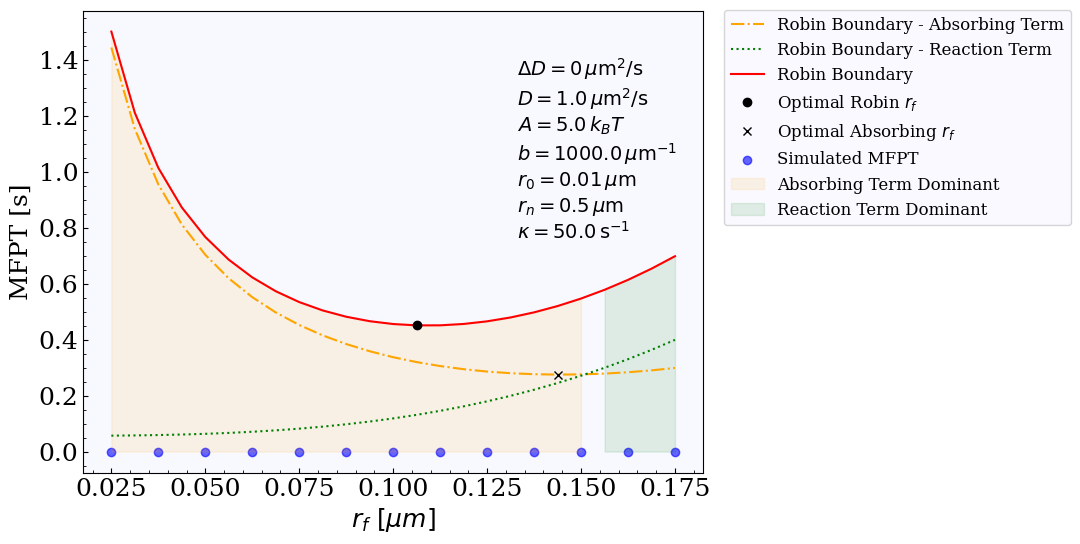

In [28]:
# Plot the MFPT as a function of r_f

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(rf_vals, tau1, label='Robin Boundary - Absorbing Term', color='orange', linestyle='-.')
ax.plot(rf_vals, tau2, label='Robin Boundary - Reaction Term', color='green', linestyle=':')
ax.plot(rf_vals, mfpt, label=f'Robin Boundary', color='red')
ax.plot(optimal_rf, mfpt[min_index], 'ko', label=f'Optimal Robin $r_f$')
ax.plot(optimal_rf_abs, tau1[min_index_abs], 'kx', label=f'Optimal Absorbing $r_f$')

# Plot simulated MFPT with error bars
#ax.errorbar(rf_vals, mfpt_simulated, yerr=std_simulated, fmt='o', color='blue', label='Simulated MFPT (N=500)', alpha=0.6)
ax.scatter(rf_vals[::2], mfpt_simulated, color='blue', alpha=0.6, label='Simulated MFPT')  # Connect the simulated points with a line


# Put the diffusion coefficient values and the potential A on the plot
text_str = rf"""
$\Delta D = 0\,\mu\mathrm{{m}}^2/\mathrm{{s}}$
$D = {D}\,\mu\mathrm{{m}}^2/\mathrm{{s}}$
$A = {A}\,k_BT$
$b = {b}\,\mu\mathrm{{m}}^{{-1}}$
$r_0 = {r_target}\,\mu\mathrm{{m}}$
$r_n = {r_n}\,\mu\mathrm{{m}}$
$\kappa = {kappa}\,\mathrm{{s}}^{{-1}}$
"""
ax.text(0.7, 0.95, text_str, transform=ax.transAxes, verticalalignment='top', fontsize=14)

# Fill the background where the absorbing term dominates (tau1 > tau2)
absorbing_dominant = tau1 >= tau2
ax.fill_between(rf_vals, 0, mfpt, where=absorbing_dominant, color='orange', alpha=0.1, label='Absorbing Term Dominant')
ax.fill_between(rf_vals, 0, mfpt, where=~absorbing_dominant, color='green', alpha=0.1, label='Reaction Term Dominant')
ax.set_xlabel(r'$r_f$ $[\mu m]$')
ax.set_ylabel('MFPT [s]')
ax.legend(fontsize=12, bbox_to_anchor=(1.02, 1.02), loc='upper left')
plt.show()

# Comparison of slow and fast diffusion

In [29]:
# Build the double integral function for a range of b and r_f values 
A = 5.0 
b = 1000.0

r_target = 0.01
r_n = 0.5 

D_slow = 0.05 
D_fast = 2.0

kappa = 1.0
rf_vals = np.linspace(0.025, 0.175, 50)

tau1_slow, tau2_slow, mfpt_slow = np.zeros(len(rf_vals)), np.zeros(len(rf_vals)), np.zeros(len(rf_vals))
tau1_fast, tau2_fast, mfpt_fast = np.zeros(len(rf_vals)), np.zeros(len(rf_vals)), np.zeros(len(rf_vals))

for i in range(len(rf_vals)):
    tau1_slow[i], tau2_slow[i], mfpt_slow[i] = compute_mfpt_with_robin_boundary(r_target, rf_vals[i], r_n, D_slow, D_slow, A, b, kappa=kappa)
    tau1_fast[i], tau2_fast[i], mfpt_fast[i] = compute_mfpt_with_robin_boundary(r_target, rf_vals[i], r_n, D_fast, D_fast, A, b, kappa=kappa)

In [30]:
# Find the optimal r_f for the slow and fast diffusion cases
min_index_slow = np.argmin(mfpt_slow)
optimal_rf_slow = rf_vals[min_index_slow]

min_index_fast = np.argmin(mfpt_fast)
optimal_rf_fast = rf_vals[min_index_fast]

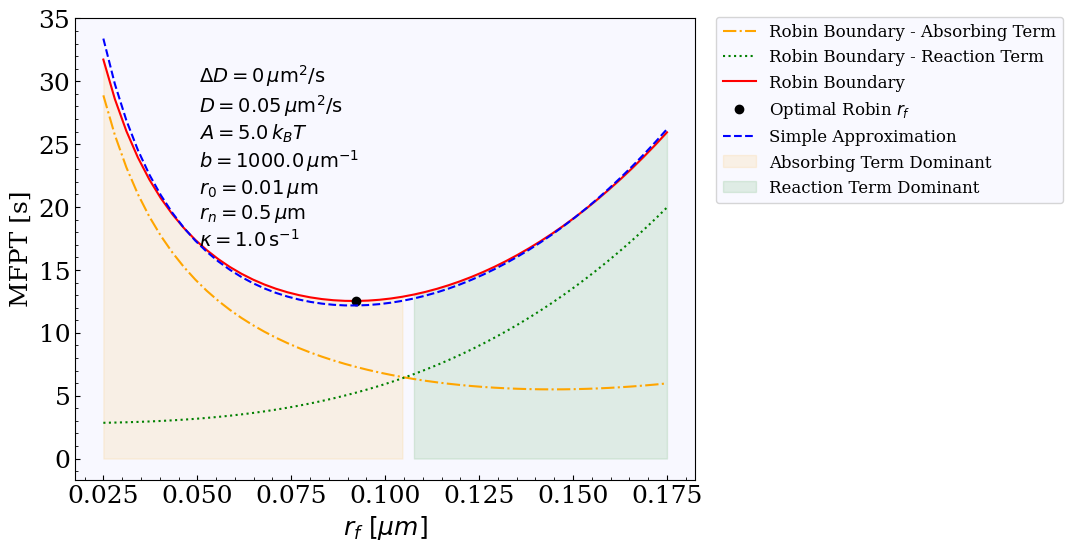

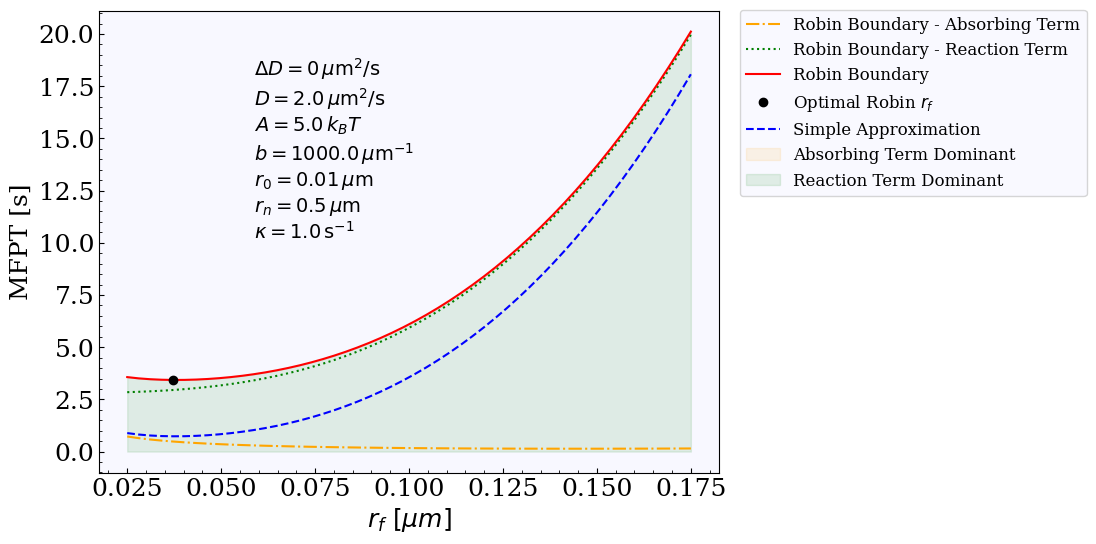

In [31]:
# Plot for the slow diffusion case
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(rf_vals, tau1_slow, label='Robin Boundary - Absorbing Term', color='orange', linestyle='-.')
ax.plot(rf_vals, tau2_slow, label='Robin Boundary - Reaction Term', color='green', linestyle=':')
ax.plot(rf_vals, mfpt_slow, label=f'Robin Boundary', color='red')
ax.plot(optimal_rf_slow, mfpt_slow[min_index_slow], 'ko', label=f'Optimal Robin $r_f$')

# Put the diffusion coefficient values and the potential A on the plot
text_str = rf"""
$\Delta D = 0\,\mu\mathrm{{m}}^2/\mathrm{{s}}$
$D = {D_slow}\,\mu\mathrm{{m}}^2/\mathrm{{s}}$
$A = {A}\,k_BT$
$b = {b}\,\mu\mathrm{{m}}^{{-1}}$
$r_0 = {r_target}\,\mu\mathrm{{m}}$
$r_n = {r_n}\,\mu\mathrm{{m}}$
$\kappa = {kappa}\,\mathrm{{s}}^{{-1}}$
"""
ax.text(0.2, 0.95, text_str, transform=ax.transAxes, verticalalignment='top', fontsize=14)

# Plot the simple approximation for the slow diffusion case
simple_approx_slow = np.array([simple_approx(r_target, rf, r_n, D_slow, D_slow, kappa, A=None) for rf in rf_vals])
ax.plot(rf_vals, simple_approx_slow, label='Simple Approximation', color='blue', linestyle='--')

# Fill the background where the absorbing term dominates (tau1 > tau2)
absorbing_dominant = tau1_slow >= tau2_slow
ax.fill_between(rf_vals, 0, mfpt_slow, where=absorbing_dominant, color='orange', alpha=0.1, label='Absorbing Term Dominant')
ax.fill_between(rf_vals, 0, mfpt_slow, where=~absorbing_dominant, color='green', alpha=0.1, label='Reaction Term Dominant')
ax.set_xlabel(r'$r_f$ $[\mu m]$')
ax.set_ylabel('MFPT [s]')
ax.legend(fontsize=12, bbox_to_anchor=(1.02, 1.02), loc='upper left')
plt.show()


# Plot for the fast diffusion case
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(rf_vals, tau1_fast, label='Robin Boundary - Absorbing Term', color='orange', linestyle='-.')
ax.plot(rf_vals, tau2_fast, label='Robin Boundary - Reaction Term', color='green', linestyle=':')
ax.plot(rf_vals, mfpt_fast, label=f'Robin Boundary', color='red')
ax.plot(optimal_rf_fast, mfpt_fast[min_index_fast], 'ko', label=f'Optimal Robin $r_f$')

# Put the diffusion coefficient values and the potential A on the plot
text_str = rf"""
$\Delta D = 0\,\mu\mathrm{{m}}^2/\mathrm{{s}}$
$D = {D_fast}\,\mu\mathrm{{m}}^2/\mathrm{{s}}$
$A = {A}\,k_BT$
$b = {b}\,\mu\mathrm{{m}}^{{-1}}$
$r_0 = {r_target}\,\mu\mathrm{{m}}$
$r_n = {r_n}\,\mu\mathrm{{m}}$
$\kappa = {kappa}\,\mathrm{{s}}^{{-1}}$
"""
ax.text(0.25, 0.95, text_str, transform=ax.transAxes, verticalalignment='top', fontsize=14)

# Plot the simple approximation for the fast diffusion case
simple_approx_fast = np.array([simple_approx(r_target, rf, r_n, D_fast, D_fast, kappa, A=None) for rf in rf_vals])
ax.plot(rf_vals, simple_approx_fast, label='Simple Approximation', color='blue', linestyle='--')

# Fill the background where the absorbing term dominates (tau1 > tau2)
absorbing_dominant = tau1_fast >= tau2_fast
ax.fill_between(rf_vals, 0, mfpt_fast, where=absorbing_dominant, color='orange', alpha=0.1, label='Absorbing Term Dominant')
ax.fill_between(rf_vals, 0, mfpt_fast, where=~absorbing_dominant, color='green', alpha=0.1, label='Reaction Term Dominant')
ax.set_xlabel(r'$r_f$ $[\mu m]$')
ax.set_ylabel('MFPT [s]')
ax.legend(fontsize=12, bbox_to_anchor=(1.02, 1.02), loc='upper left')
plt.show()  


# Scaling with diffusion coefficient

In [52]:
D_vals = np.linspace(0.05, 2.0, 20)
rf_vals = np.linspace(0.1, 0.15, 50)
kappa = 100.0

print("Unitless: D_vals[0] / (kappa * r_target) =", D_vals[0] / (kappa * r_target))
print("Unitless: D_vals[-1] / (kappa * r_target) =", D_vals[-1] / (kappa * r_target))

tau1_D = np.zeros((len(D_vals), len(rf_vals)))
tau2_D = np.zeros((len(D_vals), len(rf_vals)))
mfpt_D = np.zeros((len(D_vals), len(rf_vals)))

for i in range(len(D_vals)):
    for j in range(len(rf_vals)):
        tau1_D[i, j], tau2_D[i, j], mfpt_D[i, j] = compute_mfpt_with_robin_boundary(r_target, rf_vals[j], r_n, D_vals[i], D_vals[i], A, b, kappa=kappa)

Unitless: D_vals[0] / (kappa * r_target) = 0.05
Unitless: D_vals[-1] / (kappa * r_target) = 2.0


In [53]:
# Extract the optimal rf value and the corresponding MFPT for each D value
min_mfpt_D = np.min(mfpt_D, axis=1)
optimal_rf_D = rf_vals[np.argmin(mfpt_D, axis=1)]

# Extract the value of tau1_D at the optimal rf for each D value
tau1_D_optimal = np.array([tau1_D[i, np.argmin(mfpt_D[i, :])] for i in range(len(D_vals))])
tau2_D_optimal = np.array([tau2_D[i, np.argmin(mfpt_D[i, :])] for i in range(len(D_vals))])

# Identify where the absorbing term dominates (tau1 > tau2) at the optimal rf for each D value
absorbing_dominant_D = tau1_D_optimal >= tau2_D_optimal

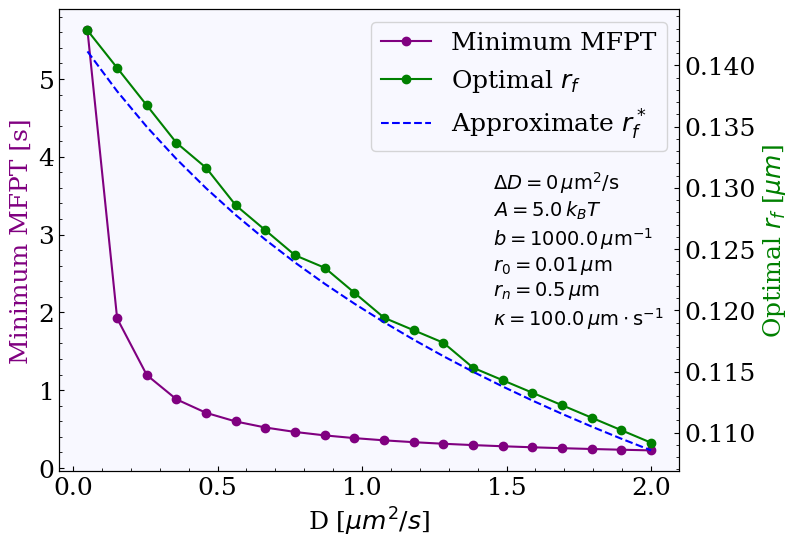

In [55]:
# Theroretical prediction for the optimal rf value as a function of D
opt_rf_theory = (kappa * r_n**3*r_target**2 / 3 * 1 / (kappa * r_target + D_vals))**(1/4)

# Plot the minimum mfpt as a function of D
fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(D_vals, min_mfpt_D, '-o', color='purple', label='Minimum MFPT', zorder=1)

ax.set_xlabel(r'D [$\mu m^2/s$]')
ax.set_ylabel(r'Minimum MFPT [s]', color='purple')

# On a secondary y-axis, plot the optimal rf value as a function of D
ax2 = ax.twinx()
ax2.plot(D_vals, optimal_rf_D, '-o', color='green', label='Optimal $r_f$')
ax2.plot(D_vals, opt_rf_theory, '--', color='blue', label='Approximate $r_f^*$')
ax2.set_ylabel(r'Optimal $r_f$ [$\mu m$]', color='green')

# Make a single legend for both plots
lines, labels = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax2.legend(lines + lines2, labels + labels2, loc='upper right')

# Put paramater values on the plot
text_str = rf"""
$\Delta D = 0\,\mu\mathrm{{m}}^2/\mathrm{{s}}$
$A = {A}\,k_BT$
$b = {b}\,\mu\mathrm{{m}}^{{-1}}$
$r_0 = {r_target}\,\mu\mathrm{{m}}$
$r_n = {r_n}\,\mu\mathrm{{m}}$
$\kappa = {kappa}\,\mu\mathrm{{m}}\cdot\mathrm{{s}}^{{-1}}$
"""
ax.text(0.7, 0.7, text_str, transform=ax.transAxes, verticalalignment='top', fontsize=14)

plt.show()


In [58]:
# Explore scaling of MFPT for (kappa, D0)-values 

D0_vals = np.linspace(0.05, 2.0, 20)
rf_vals = np.linspace(0.025, 0.15, 50)
kappa_vals = np.linspace(0.1, 10.0, 20)

tau1_Dk = np.zeros((len(kappa_vals), len(D0_vals), len(rf_vals)))
tau2_Dk = np.zeros((len(kappa_vals), len(D0_vals), len(rf_vals)))
mfpt_Dk = np.zeros((len(kappa_vals), len(D0_vals), len(rf_vals)))

for k in range(len(kappa_vals)):
    for i in range(len(D0_vals)):
        for j in range(len(rf_vals)):
            tau1_Dk[k, i, j], tau2_Dk[k, i, j], mfpt_Dk[k, i, j] = compute_mfpt_with_robin_boundary(r_target, rf_vals[j], r_n, D0_vals[i], D0_vals[i], A, b, kappa=kappa_vals[k])

In [69]:
# Save as a csv file
# Create a DataFrame to store the results
results = []
for k in range(len(kappa_vals)):
    for i in range(len(D0_vals)):
        for j in range(len(rf_vals)):
            results.append({
                'kappa': kappa_vals[k],
                'D0': D0_vals[i],
                'rf': rf_vals[j],
                'tau1': tau1_Dk[k, i, j],
                'tau2': tau2_Dk[k, i, j],
                'mfpt': mfpt_Dk[k, i, j]
            })
df = pd.DataFrame(results)
df.to_csv('robin_constD_D0_kappa_results.csv', index=False)

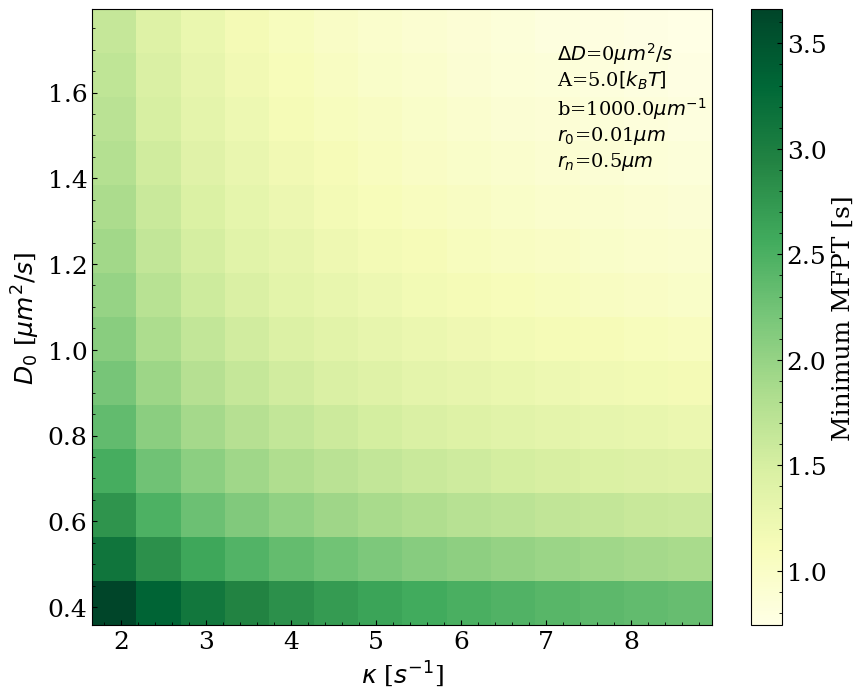

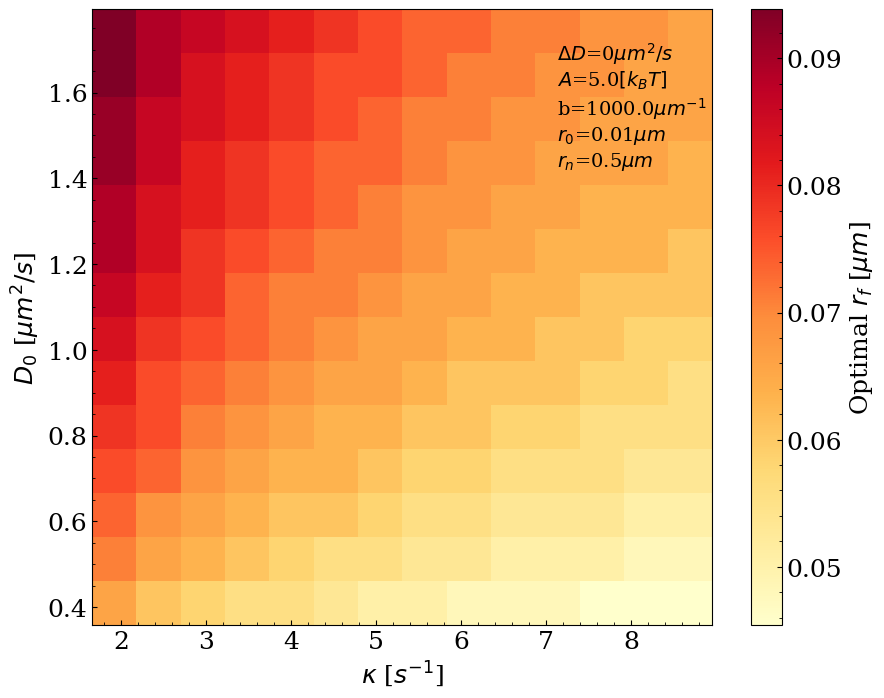

In [ ]:
# Plot the minimum MFPT as a function of D and kappa using a heatmap

# Extract the optimal rf value and the corresponding MFPT for each D value and kappa value
min_mfpt_Dk = np.min(mfpt_Dk, axis=2)
optimal_rf_Dk = rf_vals[np.argmin(mfpt_Dk, axis=2)]

slice_D_i, slice_D_f = 3, -3
slice_k_i, slice_k_f = 3, -3
sliced_mfpt_opt = min_mfpt_Dk[slice_D_i:slice_D_f, slice_k_i:slice_k_f] 
sliced_rf_opt = optimal_rf_Dk[slice_D_i:slice_D_f, slice_k_i:slice_k_f]

fig, ax = plt.subplots(figsize=(10, 8))
c = ax.imshow(min_mfpt_Dk[slice_D_i:slice_D_f, slice_k_i:slice_k_f], extent=[kappa_vals[slice_k_i], kappa_vals[slice_k_f], D0_vals[slice_D_i], D0_vals[slice_D_f]], aspect='auto', origin='lower', cmap='YlGn', 
              vmin=np.min(sliced_mfpt_opt), vmax=np.max(sliced_mfpt_opt))
ax.set_xlabel('$\kappa$ [$s^{-1}$]')
ax.set_ylabel('$D_0$ [$\mu m^2/s$]')
fig.colorbar(c, ax=ax, label='Minimum MFPT [s]')        

# Put paramater values on the plot
ax.text(0.75, 0.95, f'$\Delta D$=0$\mu m^2/s$\nA={A}$[k_BT]$\nb={b}$\mu m^{{-1}}$\n$r_0$={r_target}$\mu m$\n$r_n$={r_n}$\mu m$', 
        transform=ax.transAxes, verticalalignment='top', fontsize=14)
plt.show()


fig, ax = plt.subplots(figsize=(10, 8))
c = ax.imshow(sliced_rf_opt, extent=[kappa_vals[slice_k_i], kappa_vals[slice_k_f], D0_vals[slice_D_i], D0_vals[slice_D_f]], aspect='auto', origin='lower', cmap='YlOrRd')
ax.set_xlabel('$\kappa$ [$s^{-1}$]')
ax.set_ylabel('$D_0$ [$\mu m^2/s$]')
fig.colorbar(c, ax=ax, label='Optimal $r_f$ [$\mu m$]')
ax.text(0.75, 0.95, f'$\Delta D$=0$\mu m^2/s$\n$A$={A}$[k_BT]$\nb={b}$\mu m^{{-1}}$\n$r_0$={r_target}$\mu m$\n$r_n$={r_n}$\mu m$', 
        transform=ax.transAxes, verticalalignment='top', fontsize=14)
plt.show()

# Scaling with potential strength A

In [155]:
A_vals = np.linspace(1.0, 10.0, 19)
tau1_A = np.zeros((len(A_vals), len(rf_vals)))
tau2_A = np.zeros((len(A_vals), len(rf_vals)))
mfpt_A = np.zeros((len(A_vals), len(rf_vals)))

kappa = 50.0
D0 = 1.0

for i in range(len(A_vals)):
    for j in range(len(rf_vals)):
        tau1_A[i, j], tau2_A[i, j], mfpt_A[i, j] = compute_mfpt_with_robin_boundary(r_target, rf_vals[j], r_n, D0, D0, A_vals[i], b, kappa=kappa)

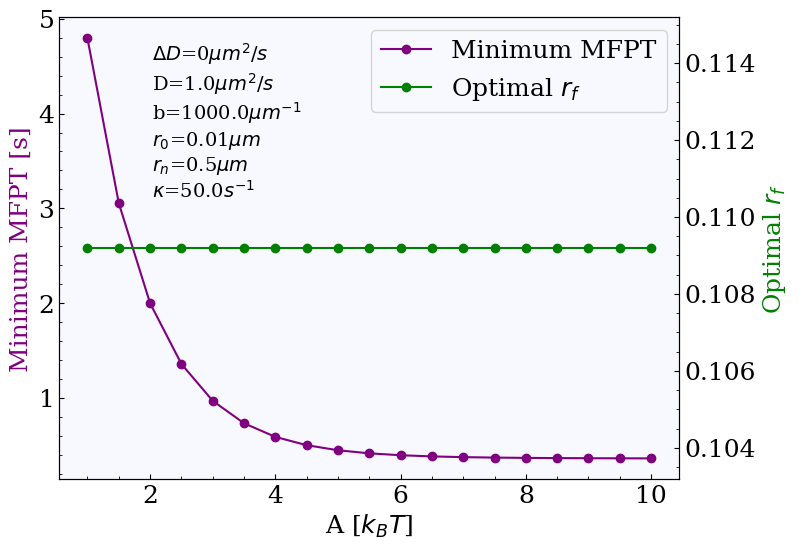

In [156]:
# Find the optimal r_f for each A value
min_mfpt_A = np.min(mfpt_A, axis=1)
optimal_rf_A = rf_vals[np.argmin(mfpt_A, axis=1)]

# Plot the minimum mfpt as a function of D 
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(A_vals, min_mfpt_A, '-o', color='purple', label='Minimum MFPT')
ax.set_xlabel('A [$k_BT$]')
ax.set_ylabel('Minimum MFPT [s]', color='purple')

# On a secondary y-axis, plot the optimal rf value as a function of D
ax2 = ax.twinx()
ax2.plot(A_vals, optimal_rf_A, '-o', color='green', label='Optimal $r_f$')
ax2.set_ylabel('Optimal $r_f$', color='green')

# Make a single legend for both plots
lines, labels = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax2.legend(lines + lines2, labels + labels2, loc='upper right')

# Put paramater values on the plot
ax.text(0.15, 0.95, f'$\Delta D$=0$\mu m^2/s$\nD={D0}$\mu m^2/s$\nb={b}$\mu m^{{-1}}$\n$r_0$={r_target}$\mu m$\n$r_n$={r_n}$\mu m$\n$\kappa$={kappa}$s^{{-1}}$', 
        transform=ax.transAxes, verticalalignment='top', fontsize=14)

plt.show()

# Scaling with $\kappa$

In [ ]:
kappa_vals = np.concatenate([np.linspace(0.1, 10.0, 8), np.linspace(20.0, 120.0, 5)])
rf_vals = np.linspace(0.025, 0.15, 50)
D0 = 1.0

tau1_kap = np.zeros((len(kappa_vals), len(rf_vals)))
tau2_kap = np.zeros((len(kappa_vals), len(rf_vals)))
mfpt_kap = np.zeros((len(kappa_vals), len(rf_vals)))

for i in range(len(kappa_vals)):
    for j in range(len(rf_vals)):
        tau1_kap[i, j], tau2_kap[i, j], mfpt_kap[i, j] = compute_mfpt_with_robin_boundary(r_target, rf_vals[j], r_n, D0, D0, A, b, kappa=kappa_vals[i])

In [48]:
min_mfpt_kap = np.min(mfpt_kap, axis=1)
optimal_rf_kap = rf_vals[np.argmin(mfpt_kap, axis=1)]

# Extract the value of tau1_D at the optimal rf for each D value
tau1_kap_optimal = np.array([tau1_kap[i, np.argmin(mfpt_kap[i, :])] for i in range(len(kappa_vals))])
tau2_kap_optimal = np.array([tau2_kap[i, np.argmin(mfpt_kap[i, :])] for i in range(len(kappa_vals))])

# Identify where the absorbing term dominates (tau1 > tau2) at the optimal rf for each D value
absorbing_dominant_kap = tau1_kap_optimal >= tau2_kap_optimal
absorbing_dominant_kap

array([False, False, False, False, False, False, False,  True,  True,
        True,  True])

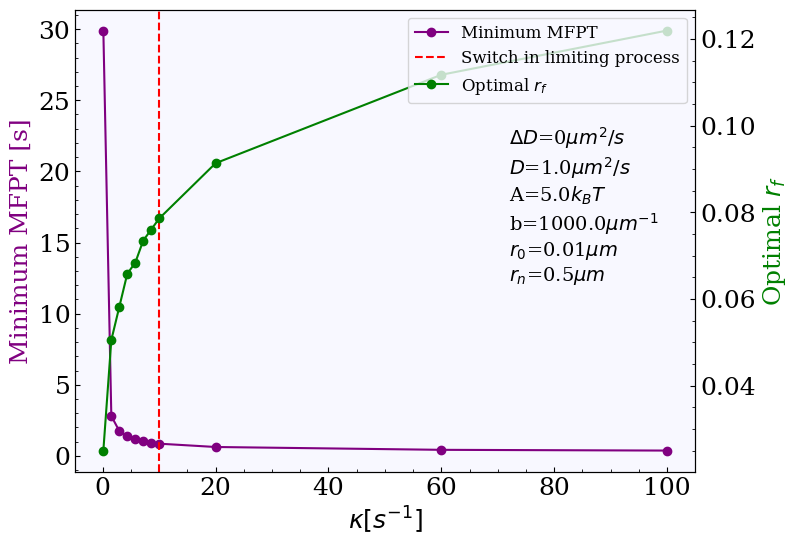

In [49]:
# Plot the minimum mfpt as a function of kappa
fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(kappa_vals, min_mfpt_kap, '-o', color='purple', label='Minimum MFPT', zorder=1)

ax.set_xlabel('$\kappa [s^{-1}]$')
ax.set_ylabel('Minimum MFPT [s]', color='purple')

# On a secondary y-axis, plot the optimal rf value as a function of D
ax2 = ax.twinx()
ax2.plot(kappa_vals, optimal_rf_kap, '-o', color='green', label='Optimal $r_f$')
ax2.set_ylabel('Optimal $r_f$', color='green')

# Plot a horisontal line indicating the value of kappa where the absorbing term starts to dominate
absorbing_dominant_indices = np.where(absorbing_dominant_kap)[0]
if len(absorbing_dominant_indices) > 0:
    kappa_threshold = kappa_vals[absorbing_dominant_indices[0]]
    ax.axvline(kappa_threshold, color='red', linestyle='--', label=f'Switch in limiting process')

# Make a single legend for both plots
lines, labels = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax2.legend(lines + lines2, labels + labels2, loc='upper right', fontsize=12)



# Put paramater values on the plot
ax.text(0.7, 0.75, f'$\Delta D$=0$\mu m^2/s$\n$D$={D0}$\mu m^2/s$\nA={A}$k_BT$\nb={b}$\mu m^{{-1}}$\n$r_0$={r_target}$\mu m$\n$r_n$={r_n}$\mu m$', 
        transform=ax.transAxes, verticalalignment='top', fontsize=14)

plt.show()

# Test for fixed droplet size $r_f$

In [ ]:
# Calculate the mfpt for a fixed droplet size and varying D 
A = 1.0 
b = 1000.0
D_vals = np.linspace(0.05, 5.0, 20)

r_target = 0.01
rf_fixed = 0.05
r_n = 0.5 

kappa = 0.01

tau1_rf_fixed, tau2_rf_fixed, mfpt_rf_fixed = np.zeros(len(D_vals)), np.zeros(len(D_vals)), np.zeros(len(D_vals))

for i in range(len(D_vals)):
    tau1_rf_fixed[i], tau2_rf_fixed[i], mfpt_rf_fixed[i] = compute_mfpt_with_robin_boundary(r_target, rf_fixed, r_n, D_vals[i], D_vals[i], A, b, kappa=kappa)

In [ ]:
# Plot the MFPT as a function of D for the fixed rf case
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(D_vals, mfpt_rf_fixed, '-o', color='purple', label=f'MFPT')
ax.set_xlabel(r'D [$\mu m^2/s$]')
ax.set_ylabel(r'MFPT [s]', color='purple')

# Put paramater values on the plot
text_str = rf"""
$\Delta D = 0\,\mu\mathrm{{m}}^2/\mathrm{{s}}$
$A = {A}\,k_BT$
$b = {b}\,\mu\mathrm{{m}}^{{-1}}$
$r_0 = {r_target}\,\mu\mathrm{{m}}$
$r_f={rf_fixed}\,\mu\mathrm{{m}}$
$r_n = {r_n}\,\mu\mathrm{{m}}$
$\kappa = {kappa}\,\mu\mathrm{{m}}\cdot\mathrm{{s}}^{{-1}}$
"""

ax.text(0.7, 0.75, text_str, transform=ax.transAxes, verticalalignment='top', fontsize=14)
ax.legend(fontsize=12)
plt.show()